In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import warnings
import os 
from pathlib import Path

import zarr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import matplotlib.colors as mcolors
from matplotlib import gridspec
import seaborn as sns
from dotenv import dotenv_values

from hm3d_utils.plotting import plot_clusters_collapsed, plot_single_cluster


In [3]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_03"
os.makedirs(OUTDIR, exist_ok=True)

ST_FP = DATADIR / "9_objects" / "spatial" / 'hypomap3d_spatial_voxel_level.zarr'
OVERVIEW_FP = OUTDIR / "dmh_cluster_overview.tsv"

In [4]:
store = zarr.open(ST_FP, mode='r')

In [5]:
dmh_cluster_overview = pd.read_csv(OVERVIEW_FP, delimiter="\t")
dmh_cluster_overview["L2_ID"] = dmh_cluster_overview.L2_descr.apply(lambda x: x.split(" ")[0])
dmh_cluster_overview.head(3)

,L3_ID,L3_descr,L2_descr,region_rank,relative_mass,cum_mass,flag,color_L3,color_L2,L2_ID
0,Gl3-84,Gl3-84 DMH Nr2f1,Gl2-26 DMH Nkx2-4,1,0.256136,0.000000,NaN,#518C55,#E41A1C,Gl2-26
1,Gl3-83,Gl3-83 DMH Pdyn,Gl2-26 DMH Nkx2-4,1,0.287700,0.000000,NaN,#8AA716,#E41A1C,Gl2-26
2,Gl3-82,Gl3-82 VMH Npy2r,Gl2-25 DMH Hmx2,3,0.149167,0.385678,NaN,#8A823C,#4C71A4,Gl2-25


In [6]:
# manually overwriting some of the colors

color_mapping_L2 = {
 'Gl2-26': '#F781BF',
 'Gl2-25': '#B05B3A' ,
 'Gl2-11': '#E8D430',
 'Gl2-36': '#58386e',
 'Gb2-64': '#CB6651',
 'Gb2-57': '#FFAF13',
 'Gb2-54': "#47A265",
 'Gb2-49': '#4C71A4',
 'Gb2-43': "#E41A1C"
 }

In [7]:
dmh_cluster_overview.color_L2 = dmh_cluster_overview.L2_ID.map(color_mapping_L2)

#### Plotting several L2 cell types 

In [8]:
dmh_l2_ids = [ 'Gb2-49', 'Gb2-54','Gb2-43', 'Gl2-25', 'Gl2-26'] 

color_mapping_L2 = dmh_cluster_overview.loc[:, ["L2_ID", "color_L2"]].drop_duplicates().set_index("L2_ID").to_dict()["color_L2"]

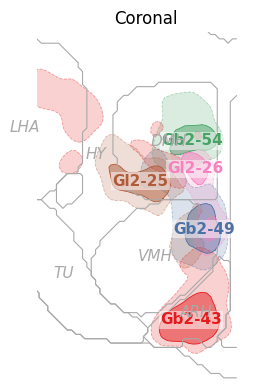

In [9]:
# Coronal view - sum over AP range, plot [DV, LM]
plot_clusters_collapsed(store, 
    dmh_l2_ids, 
    slice_range=(80, 130),
    thresholds     = [0.7, 0.9],    
    regions=['HY', 'ARH', 'DMH', 'VMH', 'LHA','TU'], 
    view='coronal',
    alphas         = [0.2, 0.5],
    linestyles = ['dashed', 'solid'],
    linewidths = [0.6,0.6],  
    axis0_range    = (60, 140)  ,
    axis1_range    = (60, 110)  ,
    figsize        = (4,4),
    label_fontsize = 11,
   region_label_fontsize = 11,
   title="Coronal",
   color_mapping = color_mapping_L2,
   save_path = OUTDIR / "DMH_L2_coronal.pdf"
)


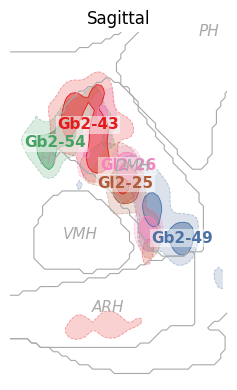

In [10]:
# Coronal view - sum over AP range, plot [DV, LM]
plot_clusters_collapsed(store, 
    dmh_l2_ids, 
    slice_range=(80, 130),
    thresholds     = [0.7, 0.9],
    regions= ['HY', 'ARH', 'DMH', 'VMH','AHN','PH'],
    view='sagittal',
    alphas         = [0.2, 0.5],
    linestyles = ['dashed', 'solid'],
    linewidths = [0.6,0.6],  
    axis0_range    = (60, 140)  ,
    axis1_range    = (80, 130)  ,
    figsize        = (4,4),
    label_fontsize = 11  ,
   region_label_fontsize = 11,
   color_mapping = color_mapping_L2,
   title="Sagittal",
   save_path = OUTDIR / "DMH_L2_sagittal.pdf"
)

### Plot all target L3 clusters

In [11]:
target_clusters = ['Gb3-173','Gb3-146', 'Gb3-209', 'Gb3-197','Gl3-80','Gl3-117', 'Gl3-27', 'Gl3-83']

Gb3-173


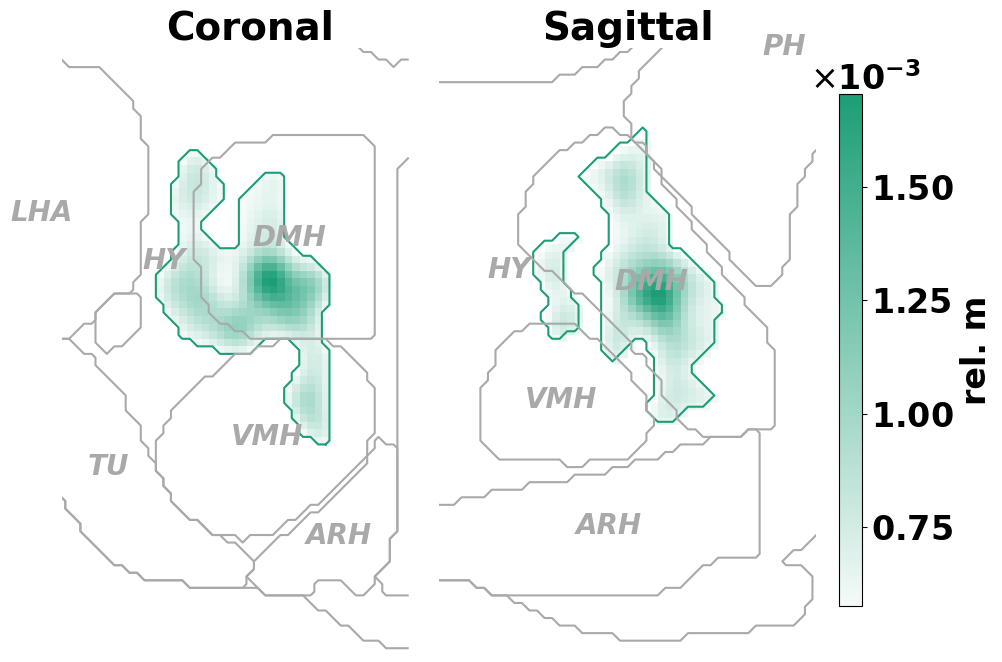

Gb3-146


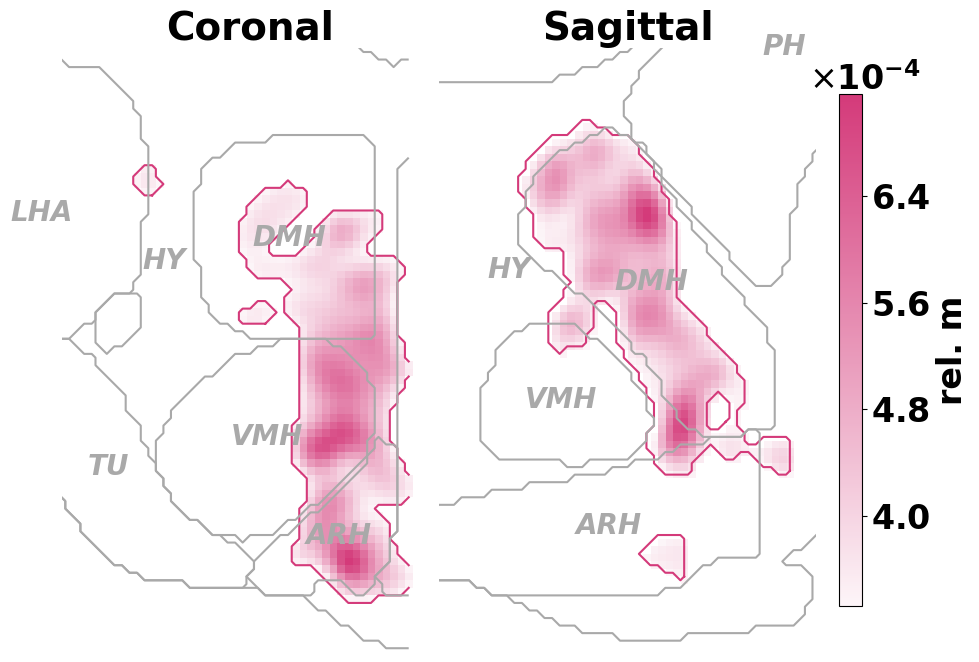

Gb3-209


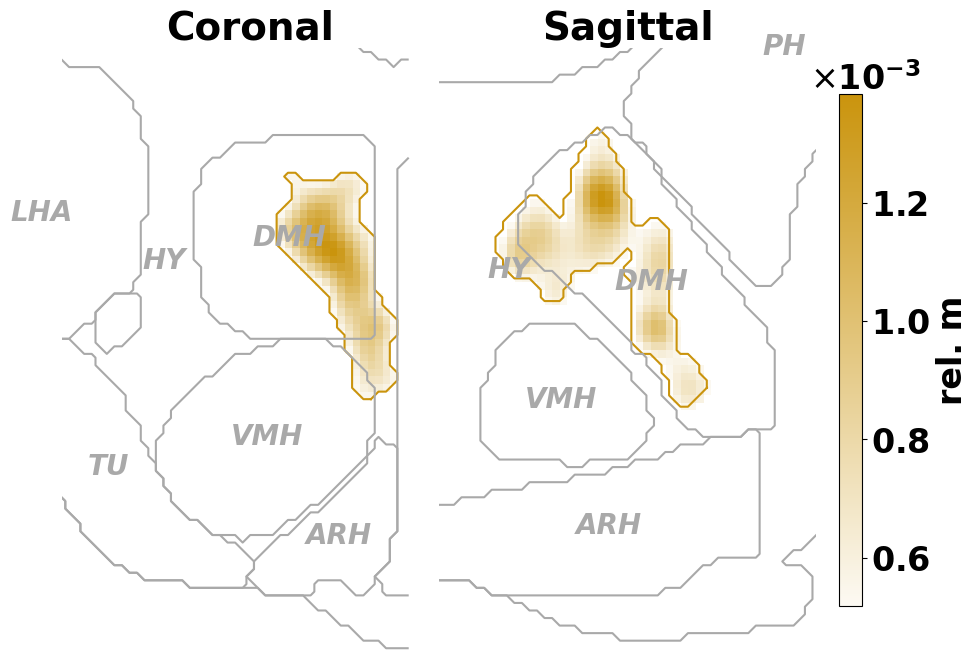

Gb3-197


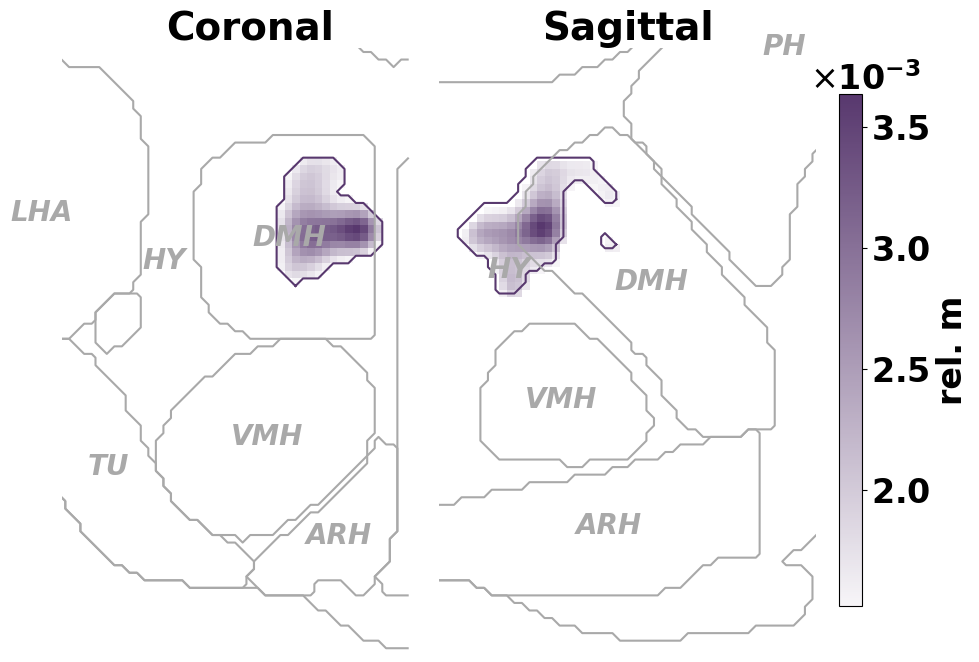

Gl3-80


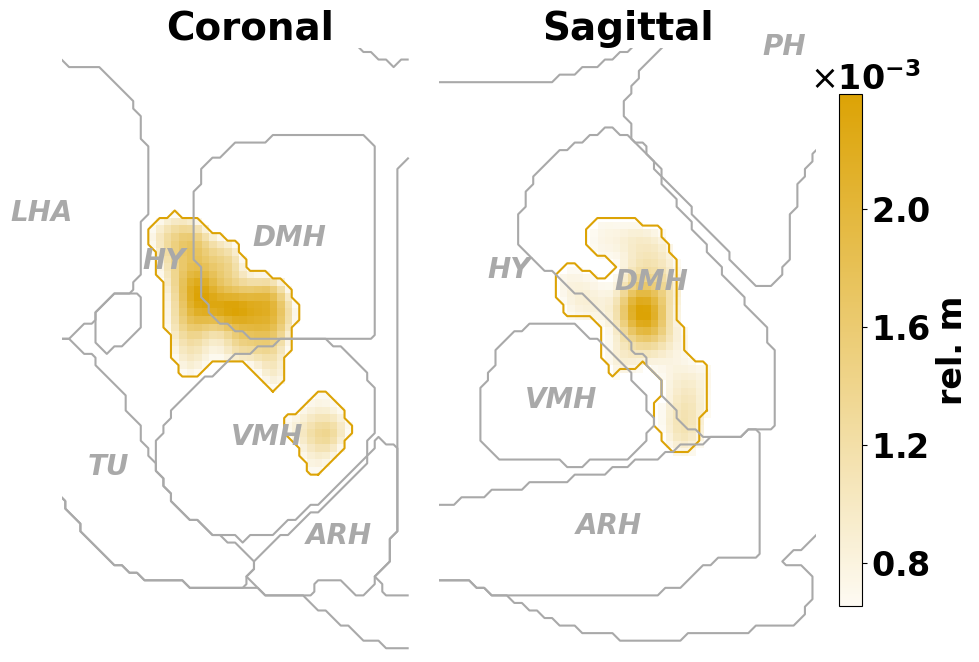

Gl3-117


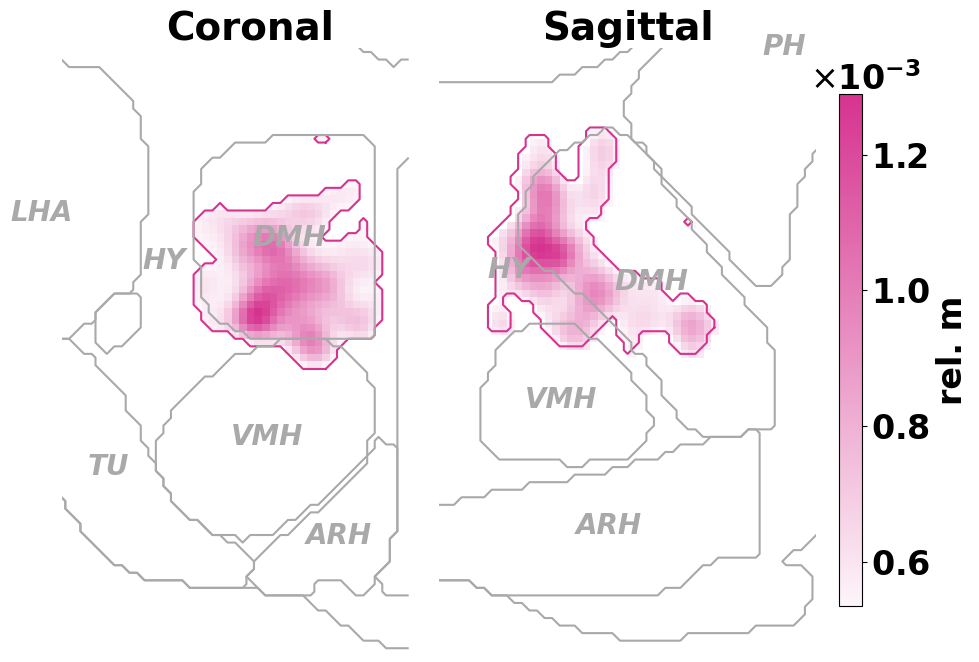

Gl3-27


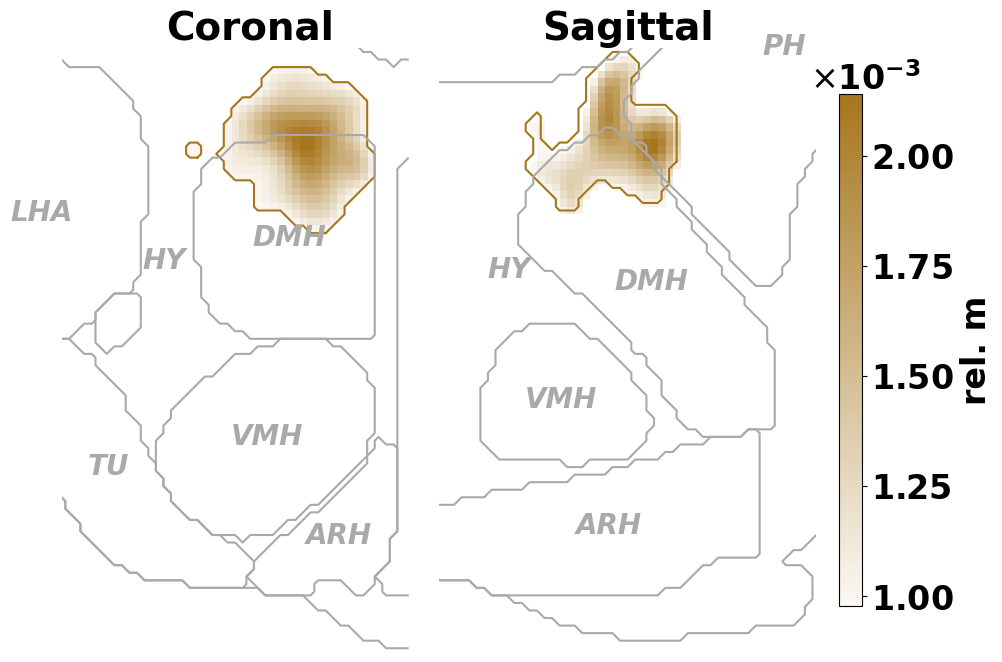

Gl3-83


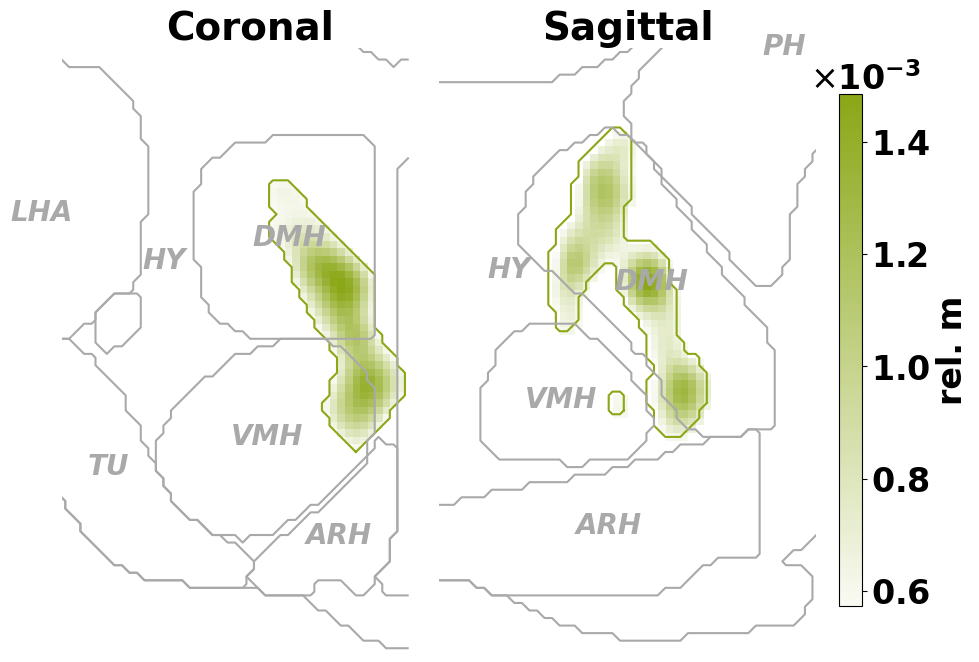

In [12]:
# All clusters in a loop
for cluster in target_clusters:
    print(cluster)
    color_to_use = dmh_cluster_overview.loc[dmh_cluster_overview['L3_ID'] == cluster, 'color_L3'].values[0]

    # ── Shared parameters ────────────────────────────────────────────────────────
    shared_params = dict(
        store          = store,
        cluster_id=cluster,
        slice_range    = (80, 130),
        mass_threshold      = 0.4,   
        axis0_range    = (60, 140),
        figsize        = (10,10),
        label_fontsize = 28,
        region_label_fontsize = 20,
        outline_linewidth = 1.5,      
        region_linewidth  = 1.5,
        fill_mode      = 'density',  
        cluster_color  = color_to_use,
        make_colorbar_bold=True,
        colorbar_n_ticks = 5,
        colorbar_tick_fontsize=24,
        colorbar_label_fontsize=24,
        title_bold=True,
        region_labels_bold=True
    )

    # ── Per-view parameters ───────────────────────────────────────────────────────
    coronal_params = dict(
        regions     = ['HY', 'ARH', 'DMH', 'VMH', 'LHA','TU'],
        view        = 'coronal',
        axis1_range = (60, 110),
        title="Coronal"
    )

    sagittal_params = dict(
        regions     = ['HY', 'ARH', 'DMH', 'VMH', 'AHN', 'PH'],
        view        = 'sagittal',
        axis1_range = (80, 130),
        add_colorbar=True,
        title="Sagittal"
    )

    # ── Figure layout based on actual data ranges ─────────────────────────────────
    dv_range   = shared_params['axis0_range']
    coronal_w  = coronal_params['axis1_range'][1]  - coronal_params['axis1_range'][0]
    sagittal_w = sagittal_params['axis1_range'][1] - sagittal_params['axis1_range'][0]
    height     = dv_range[1] - dv_range[0]
    scale      = 0.08

    fig = plt.figure(figsize=((coronal_w + sagittal_w) * scale, height * scale))
    gs  = gridspec.GridSpec(1, 4,
                            width_ratios = [coronal_w, sagittal_w, 3, 3],
                            wspace       = 0,
                            left=0, right=1, top=1, bottom=0)


    axes = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[-1]),]

    pos = axes[2].get_position()

    axes[2].set_position([
        pos.x0,
        pos.y0 + 0.1 * pos.height,
        pos.width,
        0.8 * pos.height,
    ])

    # ── Plot - merge dicts so per-view params override shared ones ────────────────
    plot_single_cluster(**{**shared_params, **coronal_params},  ax=axes[0])
    plot_single_cluster(**{**shared_params, **sagittal_params}, ax=axes[1], cbar_ax=axes[-1], )

    # Define output path and filename
    filename = OUTDIR / f'cluster_contour_{cluster}.pdf'
    # Set figure size (width, height) in inches
   # fig.set_size_inches(12, 6)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

### L4 

In [13]:
# gsx1_L4_cmap = {
#     'Gb4-388 DMH Glp1r.Slc26a7': "#d8b585", 
#     'Gb4-389 DMH Glp1r.Erg': "#8c4205", 
#     'Gb4-390 DMH Glp1r.Ghrh': "#3e566f", 
#     'Gb4-391 DMH Glp1r.Tbx19': "#7e791e", 
#     'Gb4-392 DMH Glp1r.Nfix': "#5b1e34"
# }

# _id_dict = {}
# for k, v in gsx1_L4_cmap.items():
#     _id_dict[k.split(" ")[0]] = v

# gsx1_L4_cmap = gsx1_L4_cmap | _id_dict

In [14]:
# # All clusters in a loop
# for cluster, color_to_use in gsx1_L4_cmap.items():
#     print(cluster)

#     # ── Shared parameters ────────────────────────────────────────────────────────
#     shared_params = dict(
#         store          = store,
#         cluster_id=cluster,
#         slice_range    = (80, 130),
#         mass_threshold      = 0.4,   
#         axis0_range    = (60, 140),
#         figsize        = (10, 10),
#         label_fontsize = 12,
#         region_label_fontsize = 15,
#         outline_linewidth = 1.5,      
#         region_linewidth  = 1.5,
#         fill_mode      = 'density',  
#         cluster_color  = color_to_use
#     )

#     # ── Per-view parameters ───────────────────────────────────────────────────────
#     coronal_params = dict(
#         regions     = ['HY', 'ARH', 'DMH', 'VMH', 'LHA','TU'],
#         view        = 'coronal',
#         axis1_range = (60, 110),
#     )

#     sagittal_params = dict(
#         regions     = ['HY', 'ARH', 'DMH', 'VMH', 'AHN', 'PH'],
#         view        = 'sagittal',
#         axis1_range = (80, 130),
#         add_colorbar=True,
#         colorbar_tick_fontsize=14,
#         colorbar_label_fontsize=14
#     )

#     # ── Figure layout based on actual data ranges ─────────────────────────────────
#     dv_range   = shared_params['axis0_range']
#     coronal_w  = coronal_params['axis1_range'][1]  - coronal_params['axis1_range'][0]
#     sagittal_w = sagittal_params['axis1_range'][1] - sagittal_params['axis1_range'][0]
#     height     = dv_range[1] - dv_range[0]
#     scale      = 0.08

#     fig = plt.figure(figsize=((coronal_w + sagittal_w) * scale, height * scale))
#     gs  = gridspec.GridSpec(1, 4,
#                             width_ratios = [coronal_w, sagittal_w, 3, 3],
#                             wspace       = 0,
#                             left=0, right=1, top=1, bottom=0)


#     axes = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[-1]),]

#     pos = axes[2].get_position()

#     axes[2].set_position([
#         pos.x0,
#         pos.y0 + 0.1 * pos.height,
#         pos.width,
#         0.8 * pos.height,
#     ])

#     # ── Plot - merge dicts so per-view params override shared ones ────────────────
#     plot_single_cluster(**{**shared_params, **coronal_params},  ax=axes[0])
#     plot_single_cluster(**{**shared_params, **sagittal_params}, ax=axes[1], cbar_ax=axes[-1], )

#     # Define output path and filename
#     filename = OUTDIR / f'cluster_contour_{cluster}.pdf'
#     # Set figure size (width, height) in inches
#    # fig.set_size_inches(12, 6)
#     plt.savefig(filename, dpi=300, bbox_inches='tight')
#     plt.show()

In [15]:
# # Coronal view - sum over AP range, plot [DV, LM]
# plot_clusters_collapsed(store, 
#     _id_dict.keys(), 
#     slice_range=(80, 130),
#     thresholds     = [0.7, 0.9],    
#     regions=['HY', 'ARH', 'DMH', 'VMH', 'LHA','TU'], 
#     view='coronal',
#     alphas         = [0.2, 0.5],
#     linestyles = ['dashed', 'solid'],
#     linewidths = [0.6,0.6],  
#     axis0_range    = (60, 140)  ,
#     axis1_range    = (60, 110)  ,
#     figsize        = (10, 10),
#     label_fontsize = 11,
#    region_label_fontsize = 11,
#    color_mapping = gsx1_L4_cmap,
#    save_path = OUTDIR / "Gsx1_L4_coronal.pdf"
# )


In [16]:
# # Coronal view - sum over AP range, plot [DV, LM]
# plot_clusters_collapsed(store, 
#     _id_dict.keys(), 
#     slice_range=(80, 130),
#     thresholds     = [0.7, 0.9],
#     regions= ['HY', 'ARH', 'DMH', 'VMH','AHN','PH'],
#     view='sagittal',
#     alphas         = [0.2, 0.5],
#     linestyles = ['dashed', 'solid'],
#     linewidths = [0.6,0.6],  
#     axis0_range    = (60, 140)  ,
#     axis1_range    = (80, 130)  ,
#     figsize        = (10, 10),
#     label_fontsize = 11  ,
#    region_label_fontsize = 11,
#    color_mapping = gsx1_L4_cmap,
#    save_path = OUTDIR / "Gsx1_L4_sagittal.pdf"
# )